# Decomposition of proximity data from chromatin tracing

## Example with a simulated dataset

In this example, we will
- load some proximity data, check its qualty and visualize it
- train an LDA model and evaluate its perplexity and coherence
- visualize the results of a trained model

Import required modules

In [1]:
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import joblib
import h5py
from scipy.spatial.distance import squareform
from topic3d.datatypes import PWProxArrayStack
from topic3d.results import Topic3DResult
from topic3d.workflow.core import train_LDA_model, decompose_data
from IPython.display import Image

### Visualizing the sample data

In [2]:
data_train = PWProxArrayStack(np.load("./data/sample_exp.npy"))
data_train.shape

(1745, 946)

Plotting random examples from this ensemble shows us the diversity in individual (read, "single-cell") maps. Our goal is to use LDA to decompose this data based on patterns in proximity co-occurrence. Since the red pixels indicate the regions in proximity, LDA simply needs to find patterns in pixel co-occurrence. 

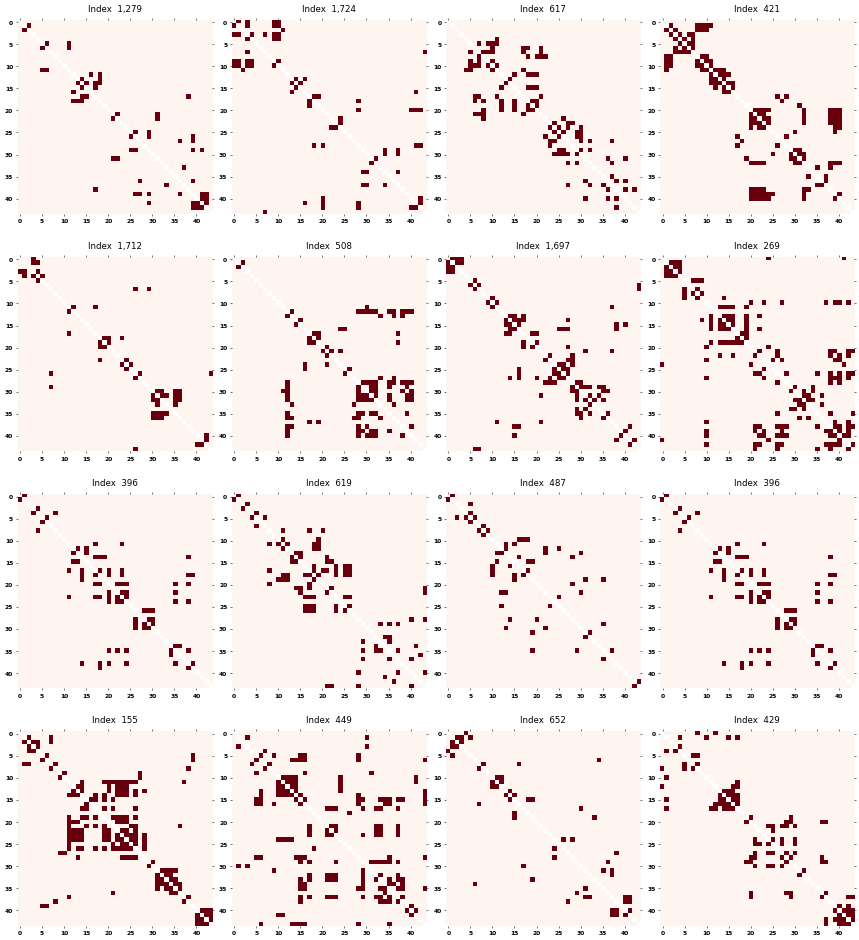

In [5]:
fig = data_train.plot_random_examples(num_items=16,
                                      random_seed=None,
                                      form="square",
                                      include_cbar=False)
fig.set_dpi(48)
fig.show()

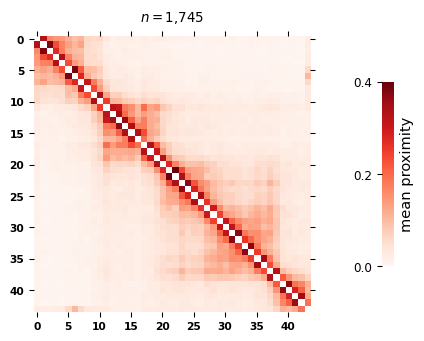

In [6]:
fig = data_train.plot_ensemble_measure(method="mean", form="square", cbar_label="mean proximity")
fig.set_dpi(96)
fig.show()

### Model training and dataset decomposition

In [7]:
params = {
    "num_components": 15,
    "max_iter": 100,
    "learning_method": "batch",
    "batch_size": 64,
    "random_state": 72,
    "evaluate_perplexity": True
}

In [8]:
model, perp_evol = train_LDA_model(params=params,
                                   data_train=data_train,)

2026-03-16 15:56:14,168 [INFO] Training data passed conformity checks
2026-03-16 15:56:14,169 [INFO] No existing model supplied. New LDA model will be created


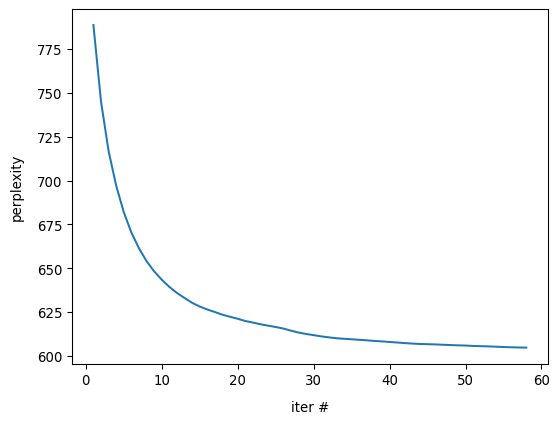

In [15]:
fig, ax = plt.subplots()
ax.plot(range(1, len(perp_evol)+1), perp_evol)
ax.set_xlabel("iter #", labelpad=10)
ax.set_ylabel("perplexity", labelpad=10)
fig.set_dpi(96)
fig.show()

In [16]:
CFMs, weights = decompose_data(data_train, model=model)

In [17]:
results = Topic3DResult(model=model, decomposition=weights)

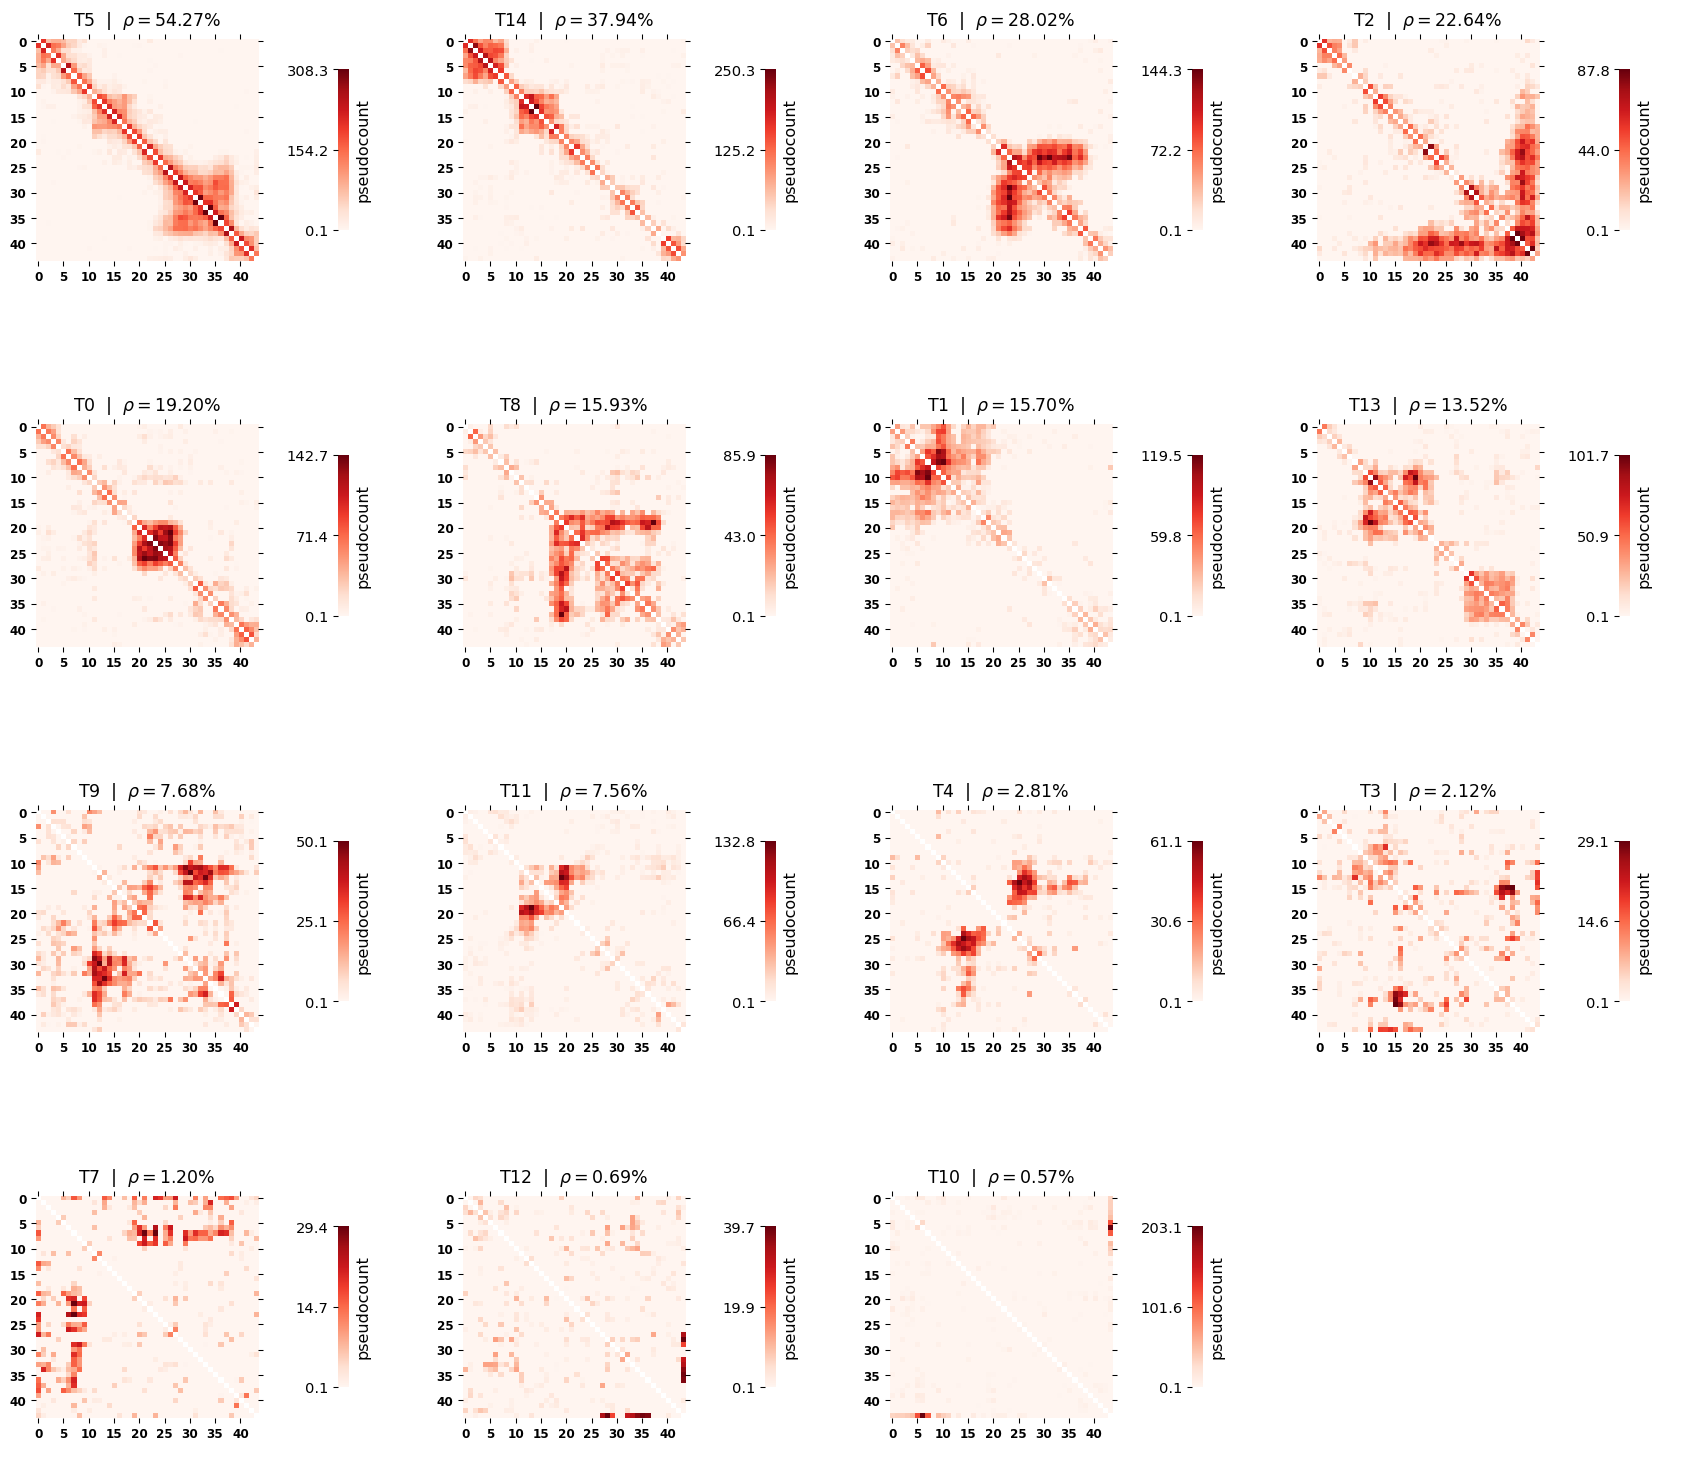

In [18]:
fig = results.plot_components(ordered=True,
                              form="square")
fig.set_dpi(96)
fig.show()

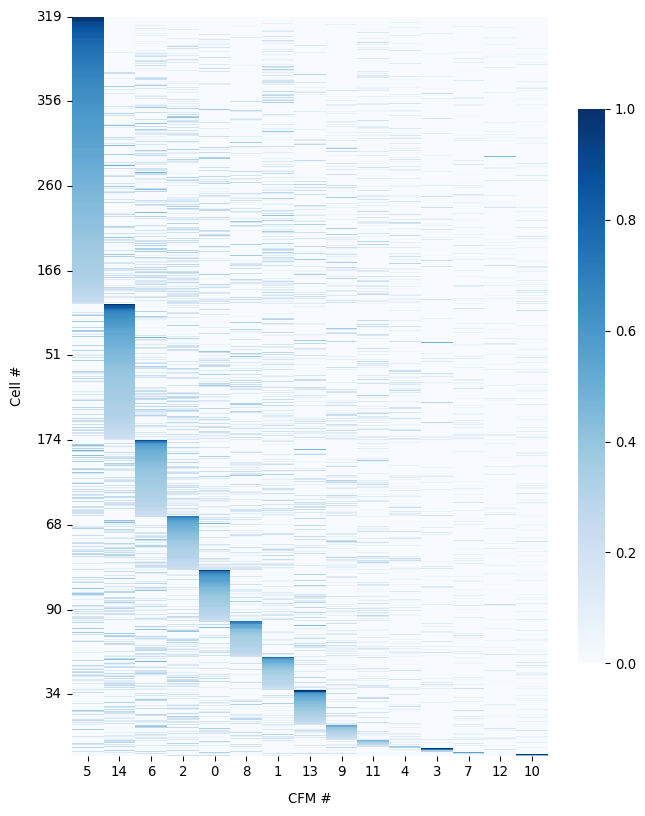

In [19]:
fig = results.plot_decomposition(ordered=True)
fig.set_dpi(96)
fig.show()